In [2]:
import numpy as np
from scipy import integrate
from scipy import optimize
from scipy.stats import norm, t 
import matplotlib.pyplot as plt
from scipy.special import logsumexp
import pandas as pd
from scipy.optimize._numdiff import approx_derivative

In [5]:
def log_likelihood(theta, y):
    n = y.shape[0]
    return theta * np.sum(y) - n * np.exp(theta)

def log_prior(theta):
    return -np.log(1 + theta**2)

def log_joint(theta, y):
    return log_likelihood(theta, y) + log_prior(theta)

def neg_log_joint(theta, y):
    return -log_joint(theta, y)

def unnorm_posterior(theta, y, m):
    return np.exp(log_joint(theta, y) - m)

def kl_integrand(theta, y, m, constant, log_g):
    log_p = log_posterior(theta, y, m, constant)

    if not np.isfinite(log_p):
        return 0.0

    p = np.exp(log_p)
    
    return (log_p - log_g(theta)) * p

def log_posterior(theta, y, m, constant):
    return log_joint(theta, y) - m - np.log(constant)


def log_skewed_laplace(theta, f, theta_map, y):
    log_joint_theta = log_joint(theta, y)
    log_joint_reflected = log_joint(2 * theta_map - theta, y)

    log_weight = log_joint_theta - logsumexp([
        log_joint_theta,
        log_joint_reflected
    ])

    return np.log(2) + f.logpdf(theta) + log_weight


In [6]:
# consider varying n and replicates

rng = np.random.default_rng(42)
n_replicates = 500
ns = [2, 4, 8, 16, 32, 64]
v = 6

results = []

for r in range(n_replicates):
    
    for n in ns: 
    
        samples = rng.poisson(lam=1.0, size=n)
        if np.sum(samples) == 0:
            print(f"All-zero dataset: n={n}, replicate={r}")

        theta_map_opt = optimize.minimize(neg_log_joint, 1.0, (samples,), method='BFGS')
        if not theta_map_opt.success:
            print(f"Warning: MAP optimization failed for n={n}, replicate={r}")
            print(theta_map_opt.message)
        theta_map = theta_map_opt.x[0]
        m = log_joint(theta_map, samples)
        norm_constant, error = integrate.quad(unnorm_posterior, -np.inf, np.inf, args=(samples, m))
        J = (
            n * np.exp(theta_map) + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
            )

        assert J > 0

        h_theta_map = 1 / J
        scale_sq = h_theta_map * (v + 1)/v
        gaussian = norm(
            loc=theta_map,
            scale=np.sqrt(h_theta_map)
        )

        student = t(
            df=v,
            loc=theta_map,
            scale=np.sqrt(scale_sq)
        )
        log_gaussian = gaussian.logpdf
        log_student = student.logpdf
        log_skew_gaussian = lambda theta: log_skewed_laplace(theta, gaussian, theta_map, samples)
        log_skew_student = lambda theta: log_skewed_laplace(theta, student, theta_map, samples)

        if np.sum(samples) == 0:
            kl_gaussian = np.inf
            kl_gaussian_skewed = np.inf
        else:
            kl_gaussian = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_gaussian))[0]
            kl_gaussian_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_skew_gaussian))[0]
             
        kl_t = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_student))[0]
        kl_t_skewed = integrate.quad(kl_integrand, -np.inf, np.inf, args=(samples, m, norm_constant, log_skew_student))[0]

        tol = 1e-6

        if kl_gaussian_skewed > kl_gaussian + tol:
            print(f"Gaussian inequality violated: n={n}, replicate={r}")

        if kl_t_skewed > kl_t + tol:
            print(f"Student-t inequality violated: n={n}, replicate={r}")

        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "skewed": False,
            "kl": kl_gaussian
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "gaussian",
            "skewed": True,
            "kl": kl_gaussian_skewed
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "student_t",
            "skewed": False,
            "kl": kl_t
            })
        results.append({
            "n": n,
            "replicate": r,
            "family": "student_t",
            "skewed": True,
            "kl": kl_t_skewed
            })

df = pd.DataFrame(results)
    
df

/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_16974/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


All-zero dataset: n=4, replicate=2
All-zero dataset: n=2, replicate=3
All-zero dataset: n=2, replicate=5
All-zero dataset: n=2, replicate=15
All-zero dataset: n=2, replicate=20
All-zero dataset: n=2, replicate=21
All-zero dataset: n=2, replicate=24
All-zero dataset: n=2, replicate=25
All-zero dataset: n=2, replicate=40
All-zero dataset: n=4, replicate=44
All-zero dataset: n=2, replicate=52
All-zero dataset: n=2, replicate=53
All-zero dataset: n=2, replicate=66
All-zero dataset: n=2, replicate=76
All-zero dataset: n=2, replicate=98
All-zero dataset: n=2, replicate=103
All-zero dataset: n=2, replicate=114
All-zero dataset: n=2, replicate=115
All-zero dataset: n=2, replicate=118
All-zero dataset: n=4, replicate=126
All-zero dataset: n=2, replicate=162
All-zero dataset: n=2, replicate=167
All-zero dataset: n=2, replicate=169
All-zero dataset: n=4, replicate=169
All-zero dataset: n=2, replicate=174
All-zero dataset: n=2, replicate=180
All-zero dataset: n=2, replicate=186
All-zero dataset: n

,n,replicate,family,skewed,kl
0,2,0,gaussian,False,0.020374
1,2,0,gaussian,True,0.010099
2,2,0,student_t,False,0.032575
3,2,0,student_t,True,0.022299
4,4,0,gaussian,False,0.009724
...,...,...,...,...,...
11995,32,499,student_t,True,0.038567
11996,64,499,gaussian,False,0.002510
11997,64,499,gaussian,True,0.000074
11998,64,499,student_t,False,0.042965


In [7]:
df.to_csv("simulations_laplace_poisson", index=False)

/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_16974/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


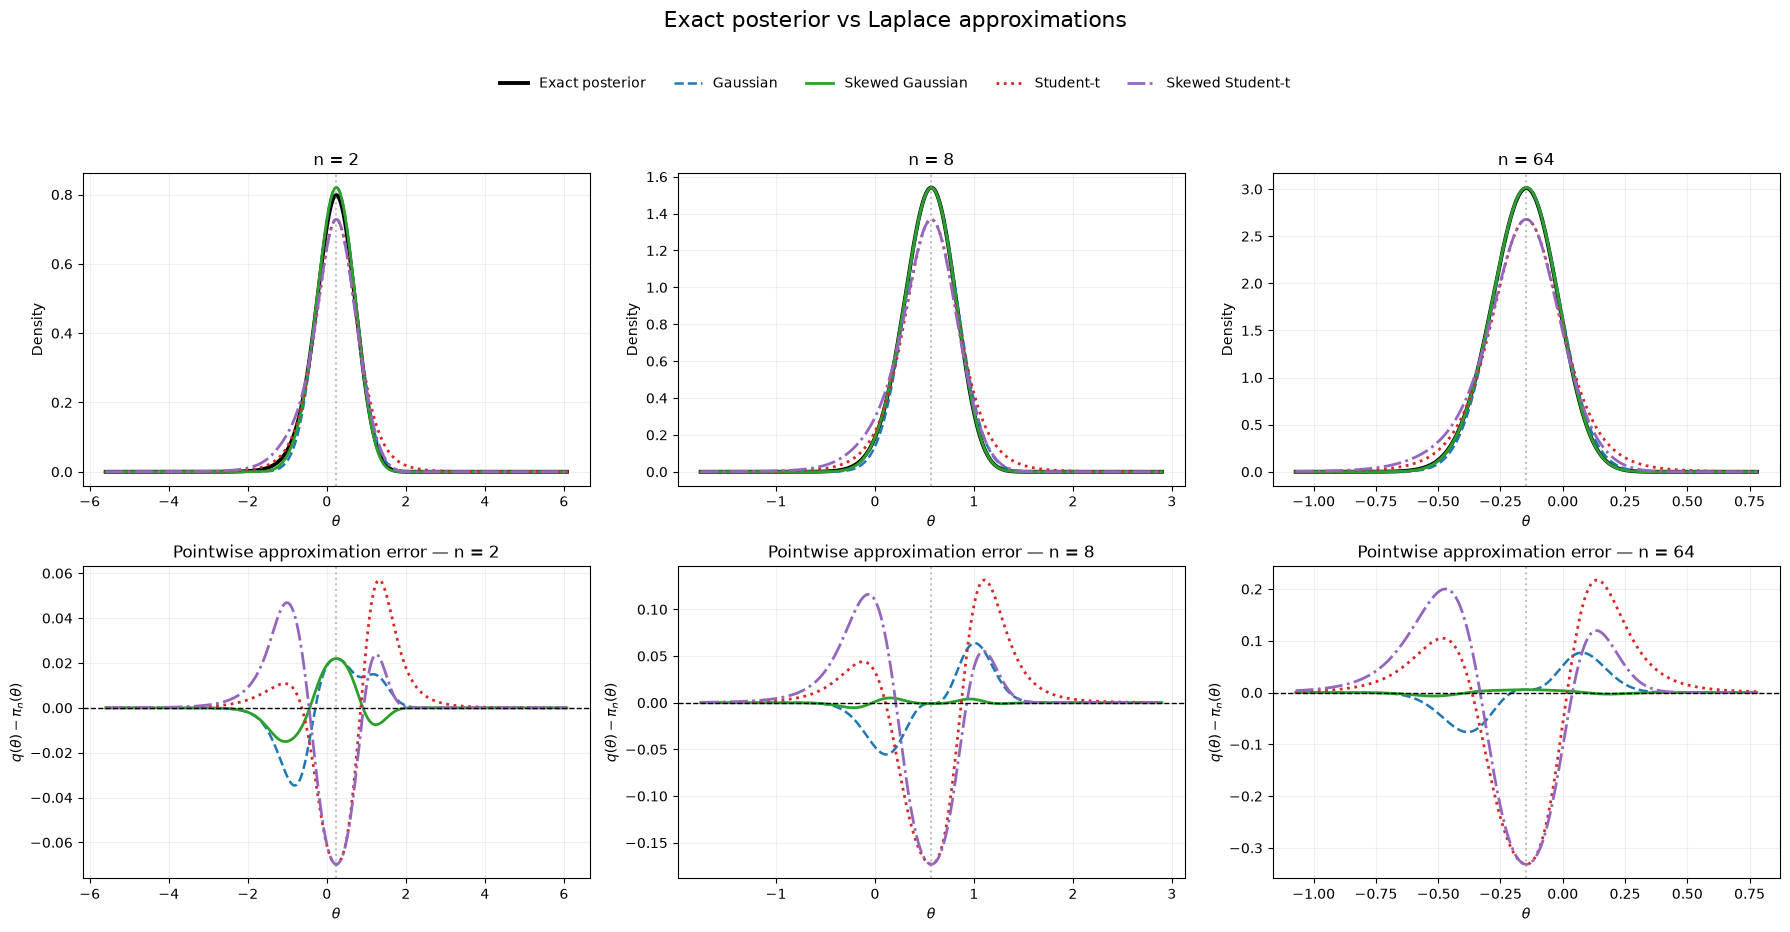

In [ ]:

# ============================================================
# EXACT POSTERIOR VS FOUR LAPLACE APPROXIMATIONS
# ============================================================

rng_plot = np.random.default_rng(42) #39 for a dataset with sum=1
selected_ns = [2, 8, 64]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

styles = {
    "Exact posterior": dict(color="black", lw=2.8, ls="-"),
    "Gaussian": dict(color="tab:blue", lw=1.8, ls="--"),
    "Skewed Gaussian": dict(color="tab:green", lw=2, ls="-"),
    "Student-t": dict(color="tab:red", lw=2, ls=":"),
    "Skewed Student-t": dict(color="tab:purple", lw=2, ls="-.")
}

datasets_plot = {}

for col, n in enumerate(selected_ns):
    samples_plot = rng_plot.poisson(lam=1.0, size=n)
    datasets_plot[n] = samples_plot.copy()

    # MAP and normalization
    result = optimize.minimize(
        neg_log_joint, [1.0],
        args=(samples_plot,), method="BFGS"
    )

    theta_map = float(result.x[0])
    m = log_joint(theta_map, samples_plot)

    norm_constant, _ = integrate.quad(
        unnorm_posterior, -np.inf, np.inf,
        args=(samples_plot, m)
    )

    # Laplace curvature
    J = (
        n * np.exp(theta_map)
        + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
    )

    gaussian = norm(
        loc=theta_map,
        scale=np.sqrt(1 / J)
    )

    student = t(
        df=v,
        loc=theta_map,
        scale=np.sqrt((v + 1) / (v * J))
    )

    # Wider window for smaller sample sizes
    width = {2: 12, 8: 9, 64: 7}[n]
    sd = np.sqrt(1 / J)

    theta_grid = np.linspace(
        theta_map - width * sd,
        theta_map + width * sd,
        2000
    )

    # Exact posterior
    posterior = np.exp(
        log_posterior(
            theta_grid, samples_plot, m, norm_constant
        )
    )

    # Skewed approximations
    # Evaluate scalar-by-scalar to reuse log_skewed_laplace
    skew_gaussian = np.exp([
        log_skewed_laplace(x, gaussian, theta_map, samples_plot)
        for x in theta_grid
    ])

    skew_student = np.exp([
        log_skewed_laplace(x, student, theta_map, samples_plot)
        for x in theta_grid
    ])

    densities = {
        "Exact posterior": posterior,
        "Gaussian": gaussian.pdf(theta_grid),
        "Skewed Gaussian": skew_gaussian,
        "Student-t": student.pdf(theta_grid),
        "Skewed Student-t": skew_student
    }

    # --------------------------------------------------------
    # TOP ROW: densities
    # --------------------------------------------------------

    ax = axes[0, col]

    for name, density in densities.items():
        ax.plot(theta_grid, density, label=name, **styles[name])

    ax.axvline(theta_map, color="gray", ls=":", alpha=0.5)
    ax.set_title(f"n = {n}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

    # --------------------------------------------------------
    # BOTTOM ROW: pointwise errors
    # --------------------------------------------------------

    ax = axes[1, col]

    for name, density in densities.items():
        if name == "Exact posterior":
            continue

        ax.plot(
            theta_grid,
            density - posterior,
            label=name,
            **styles[name]
        )

    ax.axhline(0, color="black", ls="--", lw=1)
    ax.axvline(theta_map, color="gray", ls=":", alpha=0.5)

    ax.set_title(f"Pointwise approximation error — n = {n}")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel(r"$q(\theta)-\pi_n(\theta)$")
    ax.grid(alpha=0.2)


# ============================================================
# SHARED LEGEND AND FORMATTING
# ============================================================

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    ncol=5,
    bbox_to_anchor=(0.5, 0.97),
    frameon=False
)

fig.suptitle(
    "Exact posterior vs Laplace approximations",
    fontsize=16,
    y=1.03
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


In [24]:

# ============================================================
# KL DIVERGENCES FOR THE DATASETS USED IN THE DENSITY PLOTS
# ============================================================

kl_results_plot = []

for n, y in datasets_plot.items():

    # MAP
    result = optimize.minimize(
        neg_log_joint,
        [1.0],
        args=(y,),
        method="BFGS"
    )

    theta_map = float(result.x[0])
    m = float(log_joint(theta_map, y))

    # Exact posterior normalizing constant
    norm_constant, _ = integrate.quad(
        unnorm_posterior,
        -np.inf,
        np.inf,
        args=(y, m)
    )

    # Negative Hessian at the MAP
    J = (
        n * np.exp(theta_map)
        + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
    )

    # Gaussian Laplace
    gaussian = norm(
        loc=theta_map,
        scale=np.sqrt(1 / J)
    )

    # Curvature-matched Student-t
    student = t(
        df=v,
        loc=theta_map,
        scale=np.sqrt((v + 1) / (v * J))
    )

    approximations = {
        "Gaussian": gaussian.logpdf,

        "Skewed Gaussian": lambda theta: log_skewed_laplace(
            theta, gaussian, theta_map, y
        ),

        "Student-t": student.logpdf,

        "Skewed Student-t": lambda theta: log_skewed_laplace(
            theta, student, theta_map, y
        )
    }

    # Compute the KL for every approximation
    for name, log_q in approximations.items():

        # All-zero datasets have infinite Gaussian forward KL
        if np.sum(y) == 0 and name in [
            "Gaussian", "Skewed Gaussian"
        ]:
            kl_value = np.inf

        else:
            kl_value, error = integrate.quad(
                kl_integrand,
                -np.inf,
                np.inf,
                args=(y, m, norm_constant, log_q)
            )

        kl_results_plot.append({
            "n": n,
            "dataset": y.tolist(),
            "approximation": name,
            "kl": kl_value
        })


# ============================================================
# DISPLAY RESULTS
# ============================================================

kl_plot_df = pd.DataFrame(kl_results_plot)

comparison = kl_plot_df.pivot(
    index="n",
    columns="approximation",
    values="kl"
)

comparison = comparison[[
    "Gaussian",
    "Skewed Gaussian",
    "Student-t",
    "Skewed Student-t"
]]

print("Datasets:")
for n, y in datasets_plot.items():
    print(f"n={n}: {y}, sum={np.sum(y)}")

print("\nForward KL divergences:")
print(comparison.round(6).to_string())

print("\nSkewed comparison:")
for n in comparison.index:
    diff = (
        comparison.loc[n, "Skewed Gaussian"]
        - comparison.loc[n, "Skewed Student-t"]
    )

    if diff > 0:
        winner = "Skewed Student-t"
    elif diff < 0:
        winner = "Skewed Gaussian"
    else:
        winner = "Tie"

    print(f"n={n}: difference={diff:.6f} | Better: {winner}")


Datasets:
n=2: [1 2], sum=3
n=8: [3 1 3 0 1 3 3 1], sum=15
n=64: [0 3 1 0 0 1 1 2 2 0 1 0 0 3 1 0 0 1 2 1 0 0 1 1 0 0 0 0 2 1 1 0 0 1 0 1 1
 1 1 0 0 3 3 0 0 2 0 1 3 1 1 1 1 0 0 1 2 1 2 0 1 2 0 0], sum=55

Forward KL divergences:
approximation  Gaussian  Skewed Gaussian  Student-t  Skewed Student-t
n                                                                    
2              0.020374         0.010099   0.032575          0.022299
8              0.008402         0.000463   0.046770          0.038830
64             0.003677         0.000164   0.043099          0.039585

Skewed comparison:
n=2: difference=-0.012200 | Better: Skewed Gaussian
n=8: difference=-0.038368 | Better: Skewed Gaussian
n=64: difference=-0.039421 | Better: Skewed Gaussian


/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_16974/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


 S  kl_skew_gaussian  kl_skew_student  difference
 0               inf         1.530302         inf
 1          0.295493         0.010179    0.285314
 2          0.059328         0.004100    0.055228
 3          0.010099         0.022299   -0.012200
 4          0.001445         0.041470   -0.040025
 5          0.001434         0.049127   -0.047693
 6          0.000802         0.045043   -0.044241
 7          0.000911         0.038475   -0.037563
 8          0.001858         0.033920   -0.032062
 9          0.002717         0.031605   -0.028888
10          0.003124         0.030758   -0.027634


/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_16974/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


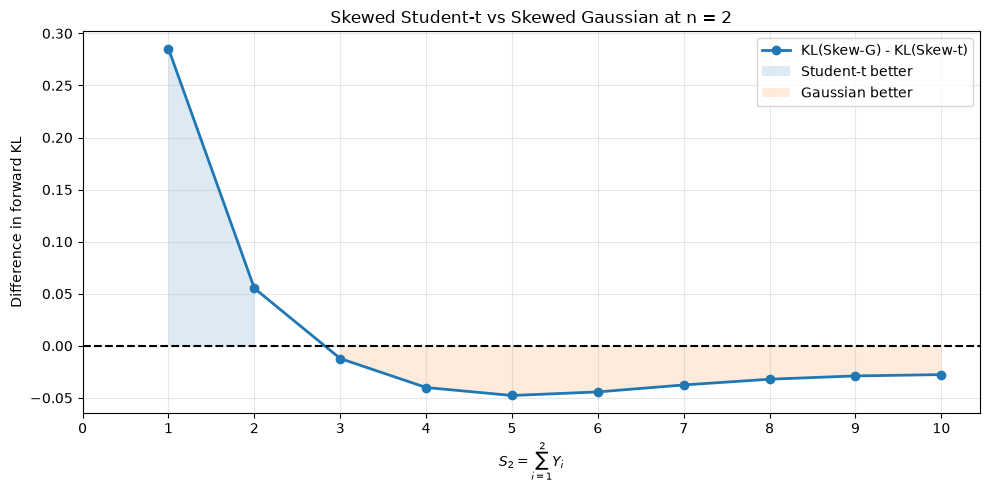

In [25]:

# ============================================================
# KL COMPARISON AS A FUNCTION OF S_2
# ============================================================

n = 2
v = 6
S_values = np.arange(0, 11)

rows = []

for S in S_values:

    # Any dataset of length 2 with sum S gives the same posterior
    y = np.array([S, 0])

    # MAP
    result = optimize.minimize(
        neg_log_joint,
        [0.0],
        args=(y,),
        method="BFGS"
    )

    theta_map = float(result.x[0])
    m = float(log_joint(theta_map, y))

    # Exact posterior normalizing constant
    norm_constant, _ = integrate.quad(
        unnorm_posterior,
        -np.inf,
        np.inf,
        args=(y, m)
    )

    # Negative Hessian at MAP
    J = (
        n * np.exp(theta_map)
        + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
    )

    gaussian = norm(
        loc=theta_map,
        scale=np.sqrt(1 / J)
    )

    student = t(
        df=v,
        loc=theta_map,
        scale=np.sqrt((v + 1) / (v * J))
    )

    log_skew_gaussian = lambda theta: log_skewed_laplace(
        theta, gaussian, theta_map, y
    )

    log_skew_student = lambda theta: log_skewed_laplace(
        theta, student, theta_map, y
    )

    # Gaussian forward KL is infinite for S = 0
    if S == 0:
        kl_sg = np.inf
    else:
        kl_sg, _ = integrate.quad(
            kl_integrand,
            -np.inf,
            np.inf,
            args=(y, m, norm_constant, log_skew_gaussian)
        )

    kl_st, _ = integrate.quad(
        kl_integrand,
        -np.inf,
        np.inf,
        args=(y, m, norm_constant, log_skew_student)
    )

    rows.append({
        "S": S,
        "kl_skew_gaussian": kl_sg,
        "kl_skew_student": kl_st,
        "difference": kl_sg - kl_st
    })

comparison_S = pd.DataFrame(rows)

print(comparison_S.to_string(index=False))


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

finite = comparison_S[
    np.isfinite(comparison_S["difference"])
]

ax.plot(
    finite["S"],
    finite["difference"],
    marker="o",
    linewidth=2,
    label="KL(Skew-G) - KL(Skew-t)"
)

ax.axhline(0, color="black", linestyle="--")

ax.fill_between(
    finite["S"],
    0,
    finite["difference"],
    where=finite["difference"] > 0,
    alpha=0.15,
    label="Student-t better"
)

ax.fill_between(
    finite["S"],
    0,
    finite["difference"],
    where=finite["difference"] < 0,
    alpha=0.15,
    label="Gaussian better"
)

ax.set_xlabel(r"$S_2 = \sum_{i=1}^2 Y_i$")
ax.set_ylabel("Difference in forward KL")
ax.set_title("Skewed Student-t vs Skewed Gaussian at n = 2")
ax.set_xticks(S_values)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:
def variational_distribution(params, family, v=6):
    mu, ro = params
    if family == 'gaussian':
        return norm(loc=mu, scale=np.exp(ro))
    else:
        return t(df=v, loc=mu, scale=np.exp(ro))      

def hellinger_objective_mc(params, family, y, m, rng, M=1000, v=6):
    sampling_distr = variational_distribution(params, family, v)
    thetas = sampling_distr.rvs(size=M, random_state=rng)
    log_g = log_joint(thetas, y) - m
    log_q = sampling_distr.logpdf(thetas)
    mc_estimate = np.mean(np.exp(0.5 * (log_g - log_q)))
    return mc_estimate

def hellinger_integrand(theta, q, y, m):
    log_g = log_joint(theta, y) - m
    log_q = q.logpdf(theta)
    return np.exp(0.5 * (log_g + log_q))

def hellinger_objective_quad(params, family, y, m, v=6):
    q = variational_distribution(params, family, v)

    value, error = integrate.quad(
        hellinger_integrand,
        -np.inf,
        np.inf,
        args=(q, y, m)
    )

    return value

def calculate_score(params, family, y, m, rng, M=1000, v=6):
    mu, ro = params
    sampling_distr = variational_distribution(params, family, v)
    thetas = sampling_distr.rvs(size=M, random_state=rng)
    log_g = log_joint(thetas, y) - m
    log_q = sampling_distr.logpdf(thetas)
    var = np.exp(2 * ro)
    if family == 'gaussian':
        der_mu = (thetas - mu) / (var) # (M,)
        der_ro = -1 + ((thetas - mu)**2 / (var)) # (M,)
    else: 
        der_mu = (thetas - mu) * (v + 1) / (v * var + (thetas - mu)**2)
        der_ro = -1 + ((v + 1) * (thetas - mu)**2) / (v * var + (thetas - mu)**2)
    gradient = np.stack([der_mu, der_ro]) # (2, M)
    return 0.5 * np.mean(gradient * np.exp (0.5 * (log_g - log_q)), axis=1)

def fit_bbvi(
        initial_params,
        family,
        y,
        m,
        rng,
        M=1000,
        v=6,
        learning_rate=0.01,
        n_iterations=1000,
             ):
    # start from some initial parameters
    # find gradient and update parameter (p_{k + 1} = p_k + learning rate * gradient)
    # save everything in a history and return that
    params = initial_params.copy()
    history = [initial_params.copy()]
    for iteration in range(n_iterations):
        gradient = calculate_score(params, family, y, m, rng, M=M, v=v)
        params = params + learning_rate * gradient
        history.append(params.copy())

    return params, np.array(history)



In [10]:
rng_data = np.random.default_rng(42)
rng_vi = np.random.default_rng(123)

n = 5
v = 6
theta_true = 0.0

samples = rng_data.poisson(
    lam=np.exp(theta_true),
    size=n
)

result = optimize.minimize(neg_log_joint, 1.0, args=(samples,), method='BFGS')
theta_map = result.x[0]
m = log_joint(theta_map, samples)
J = (
    n * np.exp(theta_map)
    + 2 * (1 - theta_map**2) / (1 + theta_map**2)**2
)


In [11]:
families = ['gaussian', 'student_t']

initializations = {
    'gaussian': {
        'laplace': np.array([theta_map, -0.5 * np.log(J)]),
        'other': np.array([0.0, -3.0])
    },
    'student_t': {
        'laplace': np.array([theta_map, 0.5 * np.log((v + 1) / (v * J))]),
        'other': np.array([0.0, -3.0])
    }
}

results = {}
for family in families:
    results[family] = {}
    for init_name, initial_params in initializations[family].items():
        rng = np.random.default_rng(123)
        params_opt, history = fit_bbvi(
                initial_params,
                family,
                samples,
                m,
                rng_vi,
                M=1000,
                v=6,
                learning_rate=0.01,
                n_iterations=5000
            )
        J_initial = hellinger_objective_quad(initial_params, family, samples, m, v=v)
        J_final = hellinger_objective_quad(params_opt, family, samples, m, v=v)
        results[family][init_name] = {
            "initial_params": initial_params.copy(),
            "params_opt": params_opt,
            "history": history,
            "J_initial": J_initial,
            "J_final": J_final
        }

/var/folders/gw/tcx_140d3b9_7gszcr9sk6wm0000gn/T/ipykernel_16974/4208611730.py:3: RuntimeWarning: overflow encountered in exp
  return theta * np.sum(y) - n * np.exp(theta)


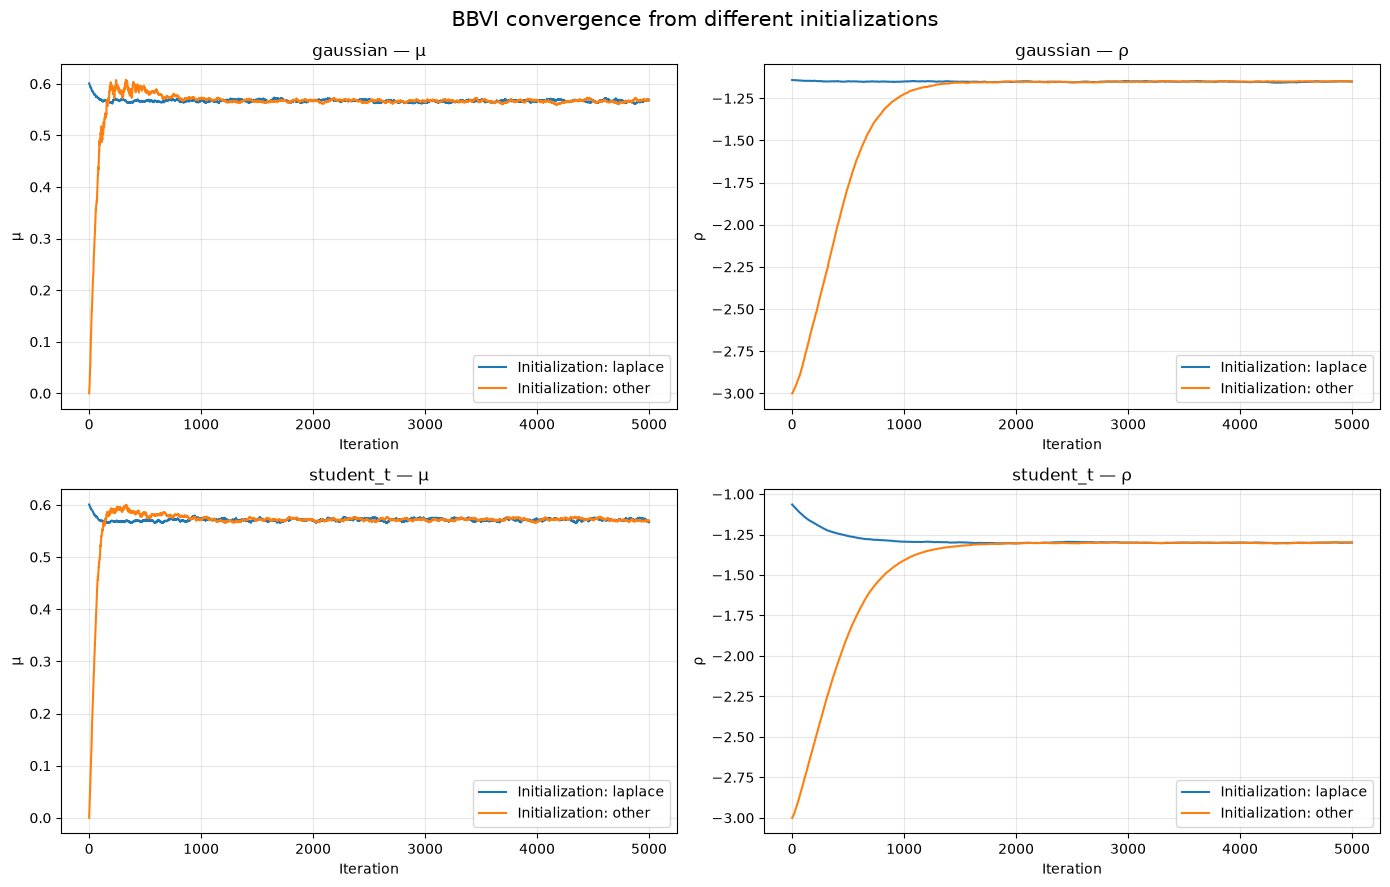

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, family in enumerate(families):
    for j, parameter in enumerate(["μ", "ρ"]):

        ax = axes[i, j]

        for init_name, result in results[family].items():
            history = result["history"]

            ax.plot(
                history[:, j],
                label=f"Initialization: {init_name}",
                linewidth=1.5
            )

        ax.set_title(f"{family} — {parameter}")
        ax.set_xlabel("Iteration")
        ax.set_ylabel(parameter)
        ax.grid(alpha=0.3)
        ax.legend()

plt.suptitle("BBVI convergence from different initializations", fontsize=15)
plt.tight_layout()
plt.show()

In [13]:
import pandas as pd

rows = []

for family in families:
    for init_name, result in results[family].items():
        rows.append({
            "family": family,
            "initialization": init_name,
            "mu_opt": result["params_opt"][0],
            "scale_opt": np.exp(result["params_opt"][1]),
            "J_initial": result["J_initial"],
            "J_final": result["J_final"],
            "improvement": result["J_final"] - result["J_initial"]
        })

summary_df = pd.DataFrame(rows)

print(summary_df.to_string(index=False))

   family initialization   mu_opt  scale_opt  J_initial  J_final  improvement
 gaussian        laplace 0.567770   0.316519   0.890521 0.891856     0.001335
 gaussian          other 0.568944   0.316493   0.228012 0.891851     0.663839
student_t        laplace 0.566759   0.272650   0.877264 0.888049     0.010785
student_t          other 0.569854   0.272862   0.271988 0.888068     0.616080
